# Inspect the model

In [24]:
import os
import sys
import random
import numpy as np # type: ignore
import cv2
from matplotlib import pyplot as plt

# Root directory of the project
ROOT_DIR = os.path.abspath(r"C:\Trabajos_CIranzo\Segmentacion")

# Import Mask RCNN
sys.path.append(os.path.join(ROOT_DIR, "Python"))  # To find local version of the library
from utils import ShrubConfig, ShrubMapDataset

import mrcnn.model as modellib
from mrcnn import utils # type: ignore
from mrcnn import visualize
from mrcnn.model import log

%matplotlib inline 

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT_DIR, "results/logs")

# Directory with train data
TRAIN_DIR = os.path.join(ROOT_DIR, "data", "encinacorba_tiles")

# Local path to trained weights file
COCO_MODEL_PATH = os.path.join(ROOT_DIR, "data/mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
    utils.download_trained_weights(COCO_MODEL_PATH)

In [2]:
def get_ax(rows=1, cols=1, size=8):
    """Return a Matplotlib Axes array to be used in
    all visualizations in the notebook. Provide a
    central point to control graph sizes.
    
    Change the default size attribute to control the size
    of rendered images
    """
    _, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
    return ax

In [8]:
# Load images to classify
dataset = ShrubMapDataset()
dataset.load_dataset(TRAIN_DIR)
dataset.prepare()

In [9]:
class InferenceConfig(ShrubConfig):
    GPU_COUNT = 1
    IMAGES_PER_GPU = 1

inference_config = InferenceConfig()
inference_config.display()


Configurations:
BACKBONE                       resnet50
BACKBONE_STRIDES               [4, 8, 16, 32, 64]
BATCH_SIZE                     1
BBOX_STD_DEV                   [0.1 0.1 0.2 0.2]
COMPUTE_BACKBONE_SHAPE         None
DETECTION_MAX_INSTANCES        100
DETECTION_MIN_CONFIDENCE       0.7
DETECTION_NMS_THRESHOLD        0.3
FPN_CLASSIF_FC_LAYERS_SIZE     1024
GPU_COUNT                      1
GRADIENT_CLIP_NORM             5.0
IMAGES_PER_GPU                 1
IMAGE_CHANNEL_COUNT            3
IMAGE_MAX_DIM                  1024
IMAGE_META_SIZE                14
IMAGE_MIN_DIM                  800
IMAGE_MIN_SCALE                0
IMAGE_RESIZE_MODE              square
IMAGE_SHAPE                    [1024 1024    3]
LEARNING_MOMENTUM              0.9
LEARNING_RATE                  0.001
LOSS_WEIGHTS                   {'rpn_class_loss': 1.0, 'rpn_bbox_loss': 1.0, 'mrcnn_class_loss': 1.0, 'mrcnn_bbox_loss': 1.0, 'mrcnn_mask_loss': 1.0}
MASK_POOL_SIZE                 14
MASK_SHAPE          

In [14]:
# Recreate the model in inference mode
model = modellib.MaskRCNN(mode="inference", 
                          config=inference_config,
                          model_dir=MODEL_DIR)

# Get path to saved weights
# Either set a specific path or find last trained weights
# model_path = os.path.join(ROOT_DIR, ".h5 file name here")
model_path = model.find_last()

# Load trained weights
print("Loading weights from ", model_path)
model.load_weights(model_path, by_name=True)

Loading weights from  C:\Trabajos_CIranzo\Segmentacion\results/logs\shrubs_cfg\mask_rcnn_shrubs_cfg_0020.h5


Include a random image from the validation set. Load the ground reference values.

original_image           shape: (1024, 1024, 3)       min:    0.00000  max:  255.00000  uint8
image_meta               shape: (14,)                 min:    0.00000  max: 1024.00000  int32
gt_class_id              shape: (0,)                  min:             max:             int32
gt_bbox                  shape: (0, 4)                min:             max:             int32
gt_mask                  shape: (0, 0, 0)             min:             max:             float64

*** No instances to display *** 



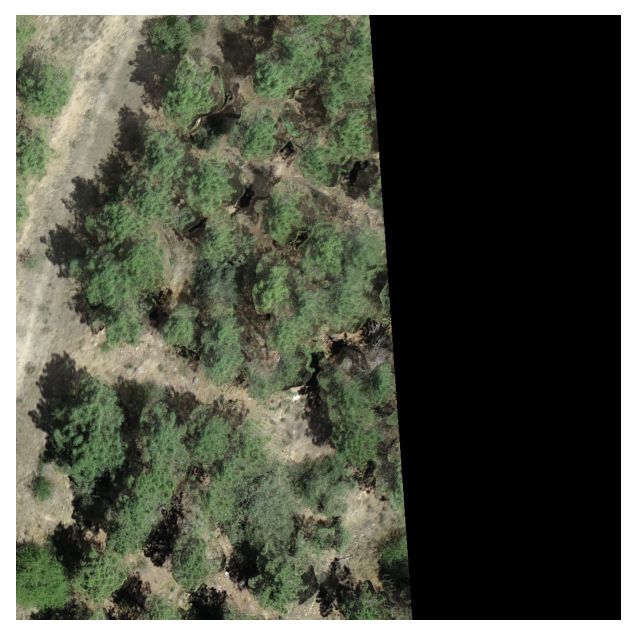

In [16]:
# Test on a random image
image_id = random.choice(dataset.image_ids)
original_image, image_meta, gt_class_id, gt_bbox, gt_mask =\
    modellib.load_image_gt(dataset, inference_config, 
                           image_id, use_mini_mask=False)

log("original_image", original_image)
log("image_meta", image_meta)
log("gt_class_id", gt_class_id)
log("gt_bbox", gt_bbox)
log("gt_mask", gt_mask)

visualize.display_instances(original_image, gt_bbox, gt_mask, gt_class_id, 
                            dataset.class_names, figsize=(8, 8))

Now ingest the image to the model and display the predictions.

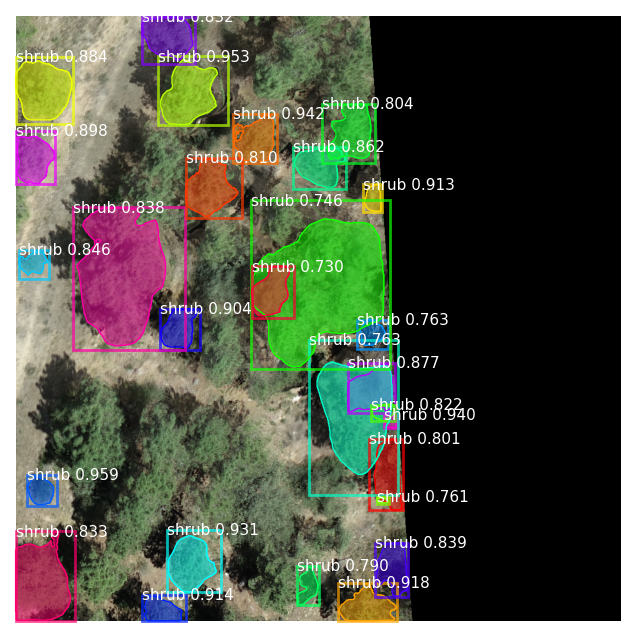

In [18]:
results = model.detect([original_image], verbose=False)

r = results[0]
visualize.display_instances(original_image, r['rois'], r['masks'], r['class_ids'], 
                            dataset.class_names, r['scores'], ax=get_ax())

## Batch predictions

In [58]:
def save_masks(img_id, masks, dataset):

    N = masks.shape[2]
    if not N:
        # No instances to display
        return
    
    merged_mask = np.any(masks, axis=2).astype(np.uint8)
    # Save as png (then rasterio will add the crs)
    img_name = os.path.basename(dataset.image_info[img_id]["path"])
    output_name = os.path.splitext(img_name)[0] + "_mask.png"
    output_path = os.path.join(ROOT_DIR, "results/shrub_map_mrcnn/png_tiles")

    cv2.imwrite(os.path.join(output_path, output_name), merged_mask)

In [59]:
for image_id in dataset.image_ids:
    
    original_image, _, _, _, _ =\
    modellib.load_image_gt(dataset, inference_config, 
                           image_id, use_mini_mask=False)
    
    results = model.detect([original_image], verbose=False)
    # Save image masks
    save_masks(image_id, results[0]["masks"], dataset)